# Crop and Weed Detection with YOLO26n

Fine-tuning a pretrained YOLO26n detector on the Crop and Weed Detection dataset (sesame crop vs. weed).

**How to run:** Runtime → Change runtime type → **T4 GPU**, then Runtime → **Run all**.

**Make sure the runtime is a T4 GPU.** The first code cell (`nvidia-smi`) must show "Tesla T4". On CPU, training takes hours.

The notebook starts from a fresh runtime: it clones the repository, installs pinned dependencies, downloads and splits the data, trains two models, evaluates the final one on the test set, and shows predictions. Total time on a free T4 GPU: about 25 minutes.

In [3]:
!nvidia-smi

Wed Nov 18 11:18:12 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   57C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [4]:
import os

%cd /content
if not os.path.exists("Object_Detection"):
    !git clone https://github.com/nursoulqxw/Object_Detection.git
%cd /content/Object_Detection

/content
Cloning into 'Object_Detection'...
remote: Enumerating objects: 32, done.
remote: Counting objects: 100% (32/32), done.
remote: Compressing objects: 100% (22/22), done.
remote: Total 32 (delta 8), reused 32 (delta 8), pack-reused 0 (from 0)
Receiving objects: 100% (32/32), 4.36 MiB | 34.34 MiB/s, done.
Resolving deltas: 100% (8/8), done.
/content/Object_Detection


In [5]:
!pip install -q -r requirements.txt

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.31.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.


In [6]:
!python src/prep_dataset.py

Using Colab cache for faster access to the 'crop-and-weed-detection-data-with-bounding-boxes' dataset.
Images found: 1300
Problems found: 0
Images with no boxes: 0
Objects of class 'crop': 1212
Objects of class 'weed': 860
Total objects: 2072
Computing hashes...
Comparing all pairs...

Distance to the most similar other image:
   0 bits: 783 images
   1 bits: 0 images
   2 bits: 432 images
   3 bits: 0 images
   4 bits: 77 images
   5 bits: 0 images
   6 bits: 4 images
   7 bits: 0 images
   8 bits: 2 images
   9 bits: 0 images
  10 bits: 2 images
  11 bits: 0 images
  12 bits: 0 images
  13 bits: 0 images
  14 bits: 0 images
  15 bits: 0 images
  16 bits: 0 images
  17 bits: 0 images
  18 bits: 0 images
  19 bits: 0 images
  20 bits: 0 images
  >20 bits: 0 images

Number of groups: 287
  groups with 2 image(s): 17
  groups with 3 image(s): 181
  groups with 5 image(s): 2
  groups with 6 image(s): 14
  groups with 7 image(s): 9
  groups with 8 image(s): 35
  groups with 9 image(s): 25


Saved res/gt_examples.png


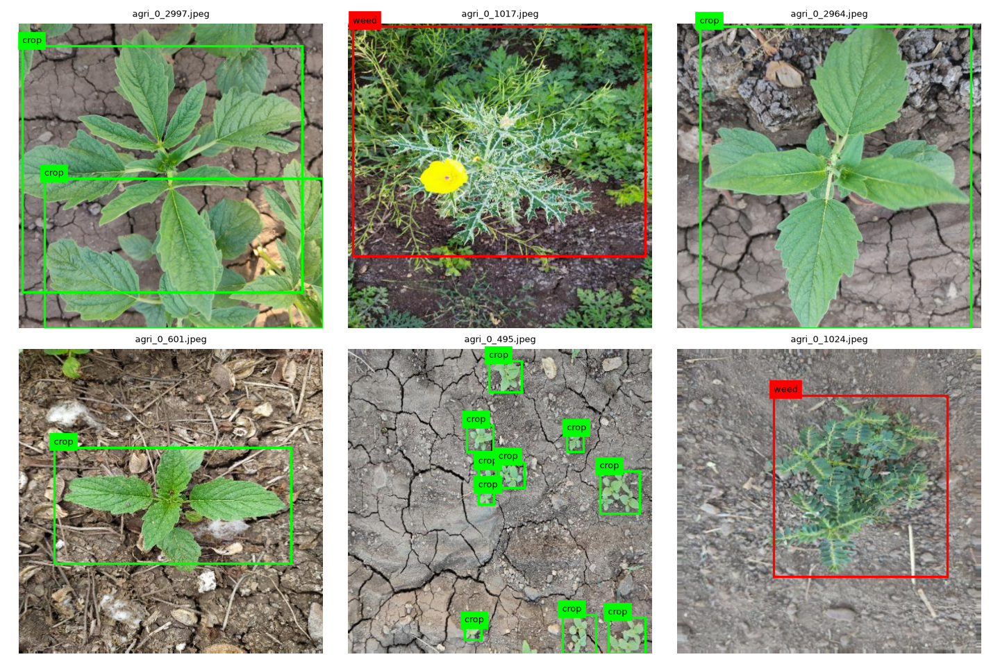

In [7]:
from IPython.display import Image, display

!python src/show_gt.py
display(Image("res/gt_examples.png"))

In [8]:
!python src/train.py configs/baseline.yml

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=data/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_

6.7 min


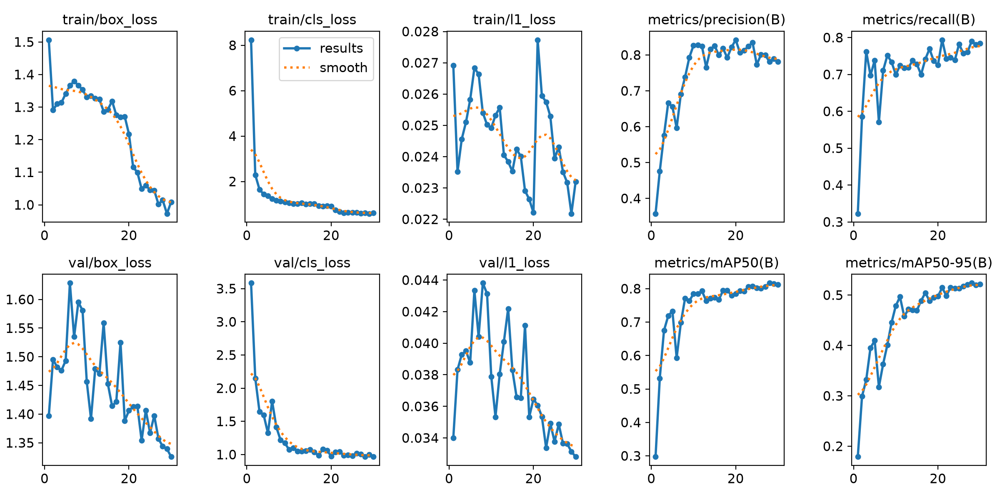

In [9]:
from IPython.display import Image, display

!cat runs/detect/baseline/train_time.txt
display(Image("runs/detect/baseline/results.png"))

## Controlled experiment (imgsz = 640)

Only one setting changes: `imgsz` 512 → 640. Everything else stays the same.

**Hypothesis:** a larger input makes small seedlings larger in pixels, so recall should increase, at the cost of about 1.5× training time.

In [12]:
!python src/train.py configs/experiment.yml

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=data/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=experiment, nbs=64, nms=None, opset=None, optimize=False, optimizer=SGD, ov

8.4 min


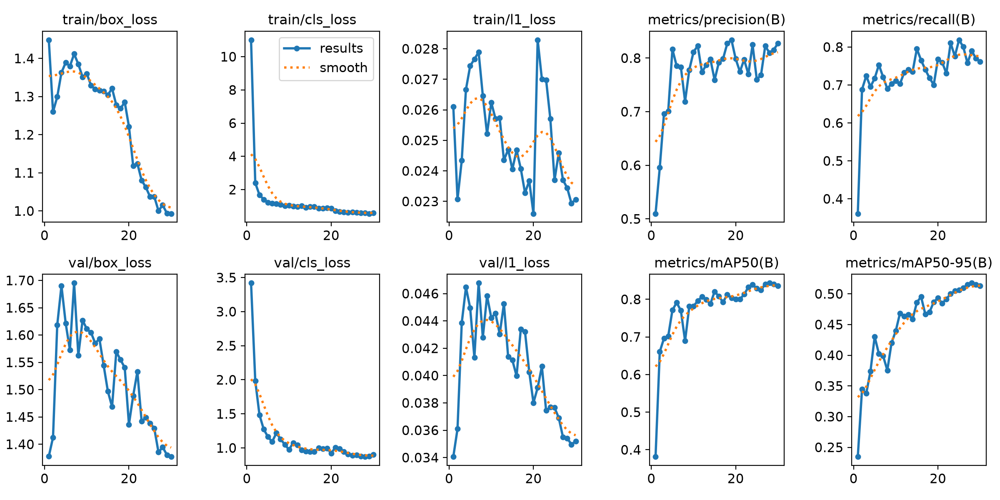

In [13]:
!cat runs/detect/experiment/train_time.txt
display(Image("runs/detect/experiment/results.png"))

In [5]:
import pandas as pd
from ultralytics import YOLO

rows = []
for name, imgsz in [("baseline", 512), ("experiment", 640)]:
    model = YOLO(f"runs/detect/{name}/weights/best.pt")
    metrics = model.val(data="data/data.yaml", split="val", imgsz=imgsz, verbose=False)
    train_time = open(f"runs/detect/{name}/train_time.txt").read().strip()
    rows.append([name, imgsz, metrics.box.mp, metrics.box.mr, metrics.box.map50, train_time])

comparison = pd.DataFrame(rows, columns=["run", "imgsz", "precision", "recall", "mAP50", "train_time"])
comparison.to_csv("res/comparison.csv", index=False)
comparison


Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 121 layers, 2,389,978 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2149.0±508.0 MB/s, size: 61.0 KB)
val: Scanning /content/Object_Detection/data/labels/val.cache... 190 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 190/190 36.2Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 12/12 5.1it/s 2.3s
                   all        190        317      0.782      0.797      0.818      0.524
Speed: 1.2ms preprocess, 3.3ms inference, 0.0ms loss, 1.6ms postprocess per image
Results saved to /content/Object_Detection/runs/detect/val-2
Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 121 layers, 2,389,978 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1616.5±450.7 MB/s, size: 51.4

,run,imgsz,precision,recall,mAP50,train_time
0,baseline,512,0.781767,0.797279,0.818209,6.5 min
1,experiment,640,0.809773,0.789720,0.843023,8.4 min


In [6]:
!python src/evaluate.py experiment 640
!cat res/test_metrics.json

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 121 layers, 2,389,978 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1710.9±808.9 MB/s, size: 66.8 KB)
val: Scanning /content/Object_Detection/data/labels/test... 194 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 194/194 2.1Kit/s 0.1s
val: New cache created: /content/Object_Detection/data/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 13/13 4.6it/s 2.8s
                   all        194        371      0.837      0.742      0.835      0.499
                  crop         94        237      0.797       0.76      0.856      0.566
                  weed        100        134      0.878      0.724      0.815      0.433
Speed: 1.8ms preprocess, 4.7ms inference, 0.0ms loss, 1.7ms postprocess per image
Results saved to /content/Object_Detection/runs/detect/experim

In [7]:
!python src/predict.py experiment 640

Saved 44 images to res/preds


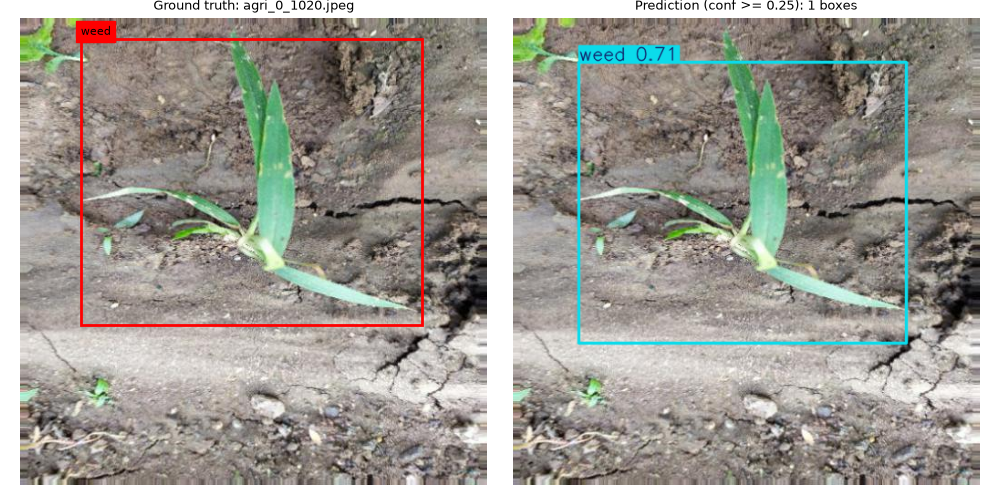

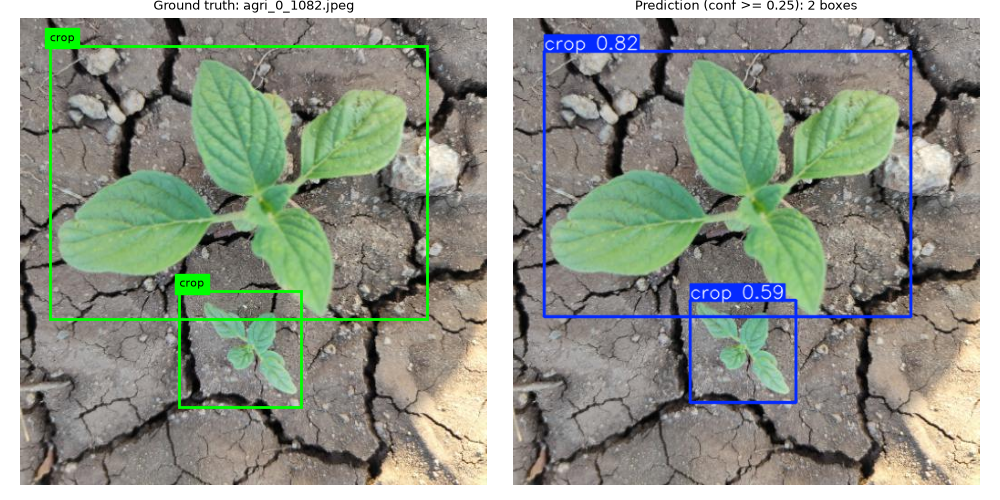

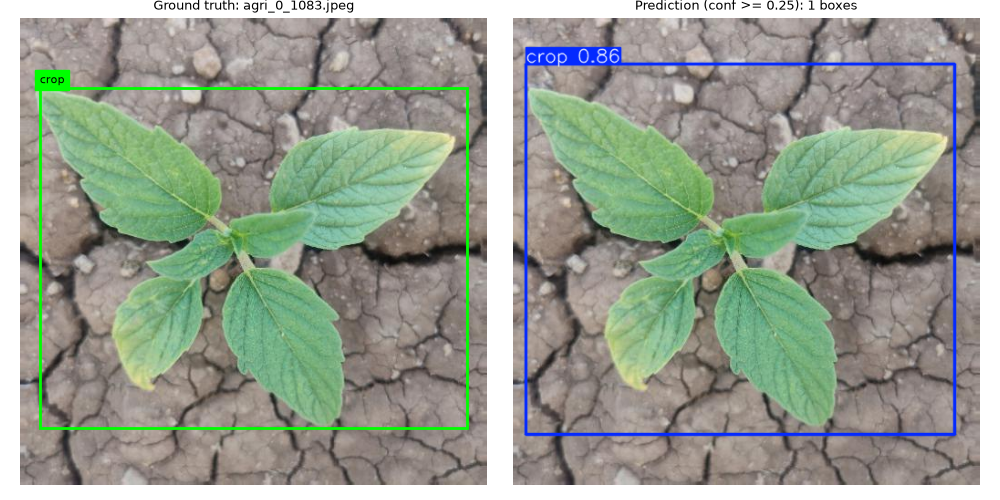

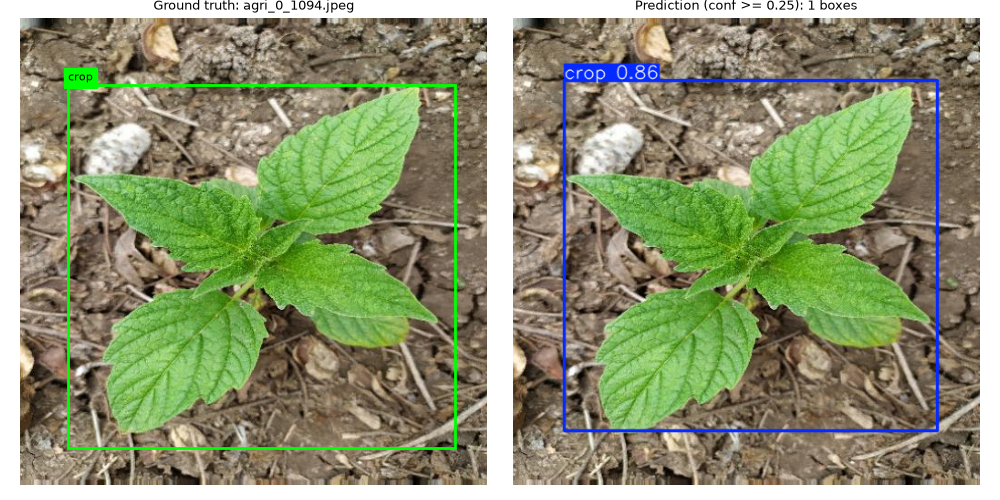

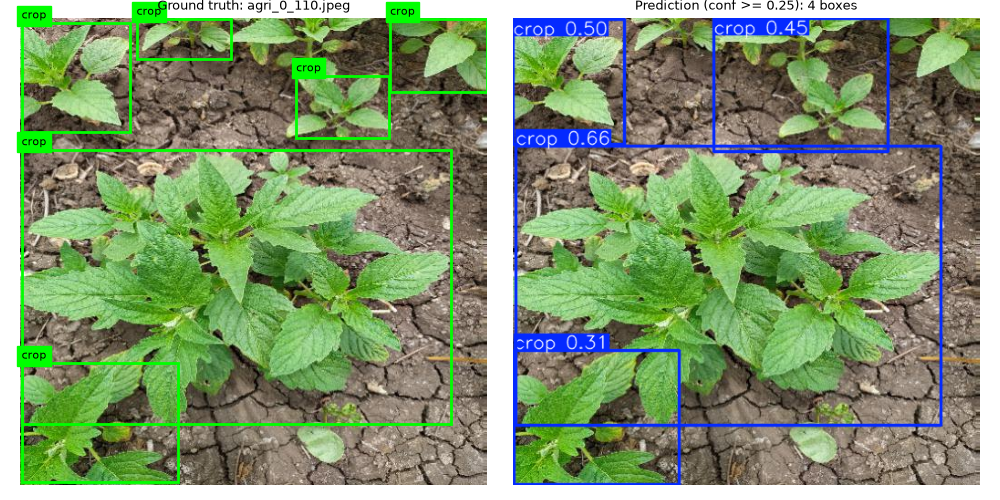

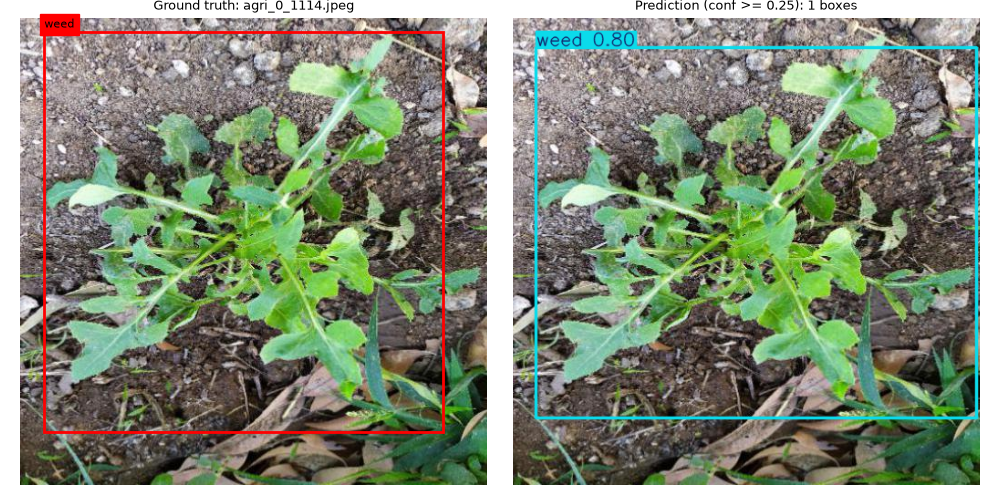

In [8]:
from pathlib import Path
from IPython.display import Image, display

for path in sorted(Path("res/preds").glob("*.png"))[:6]:
    display(Image(str(path)))

agri_0_14.jpeg: ground truth 19, predicted 9
agri_0_1499.jpeg: ground truth 11, predicted 14
agri_0_6978.jpeg: ground truth 1, predicted 3
agri_0_6707.jpeg: ground truth 1, predicted 3
agri_0_5822.jpeg: ground truth 1, predicted 3
agri_0_1590.jpeg: ground truth 4, predicted 2
agri_0_110.jpeg: ground truth 6, predicted 4
agri_0_6270.jpeg: ground truth 1, predicted 2
agri_0_4034.jpeg: ground truth 1, predicted 2
agri_0_3014.jpeg: ground truth 3, predicted 2


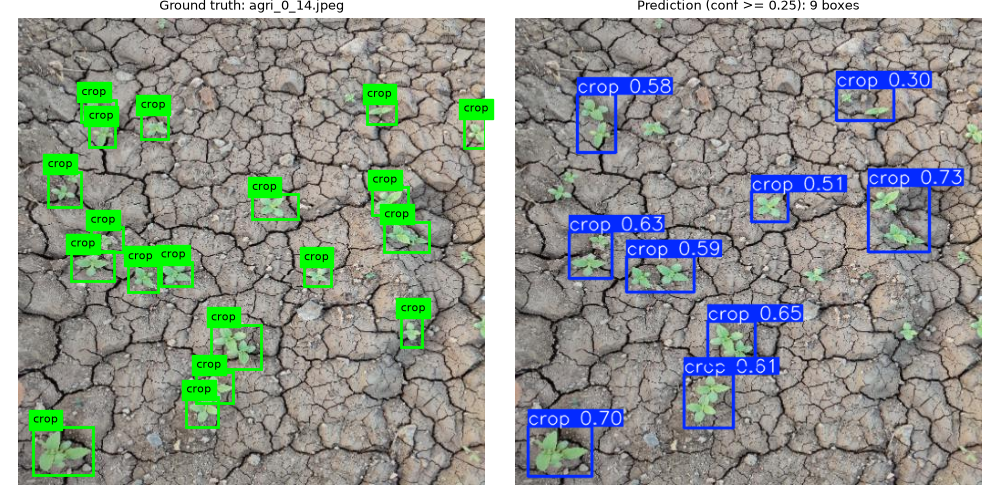

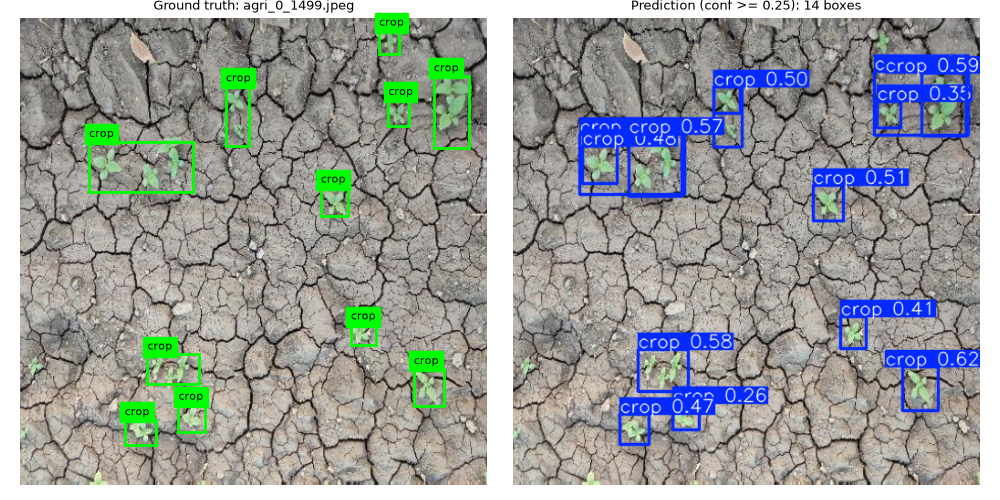

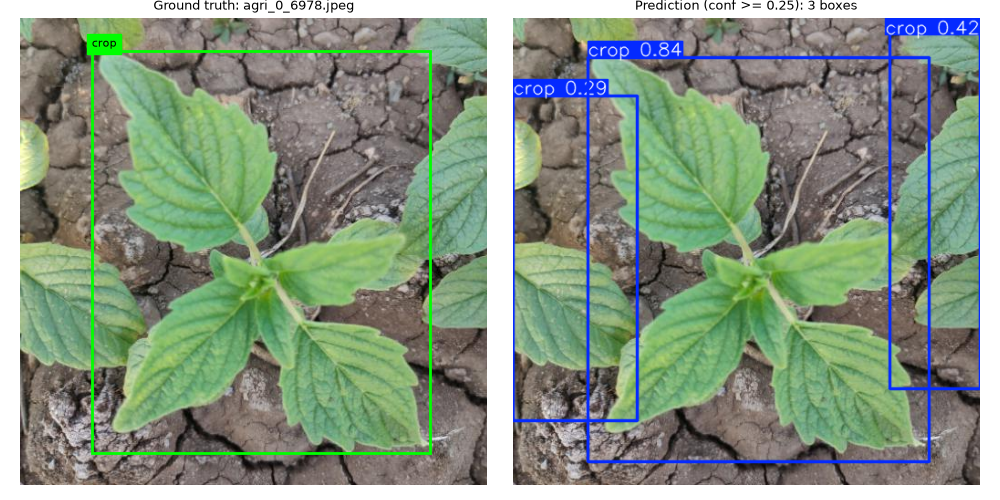

/content/Object_Detection


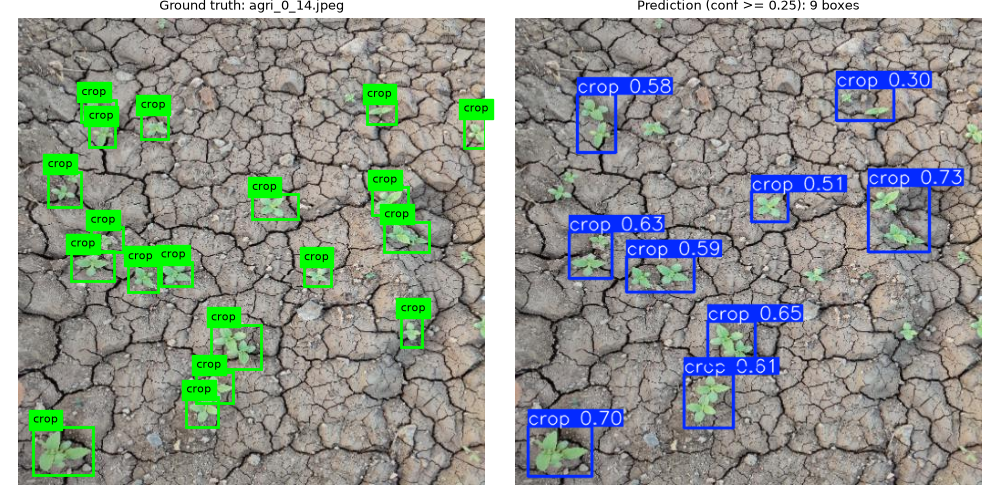

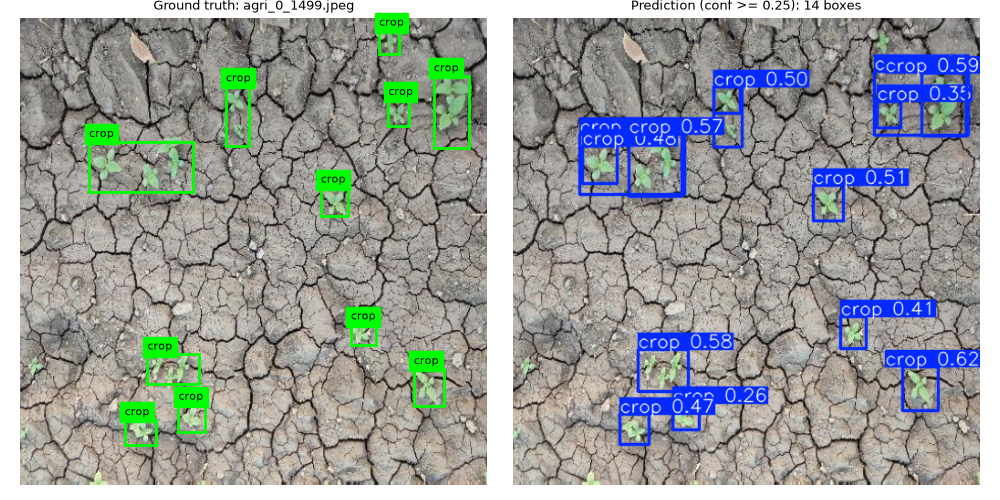

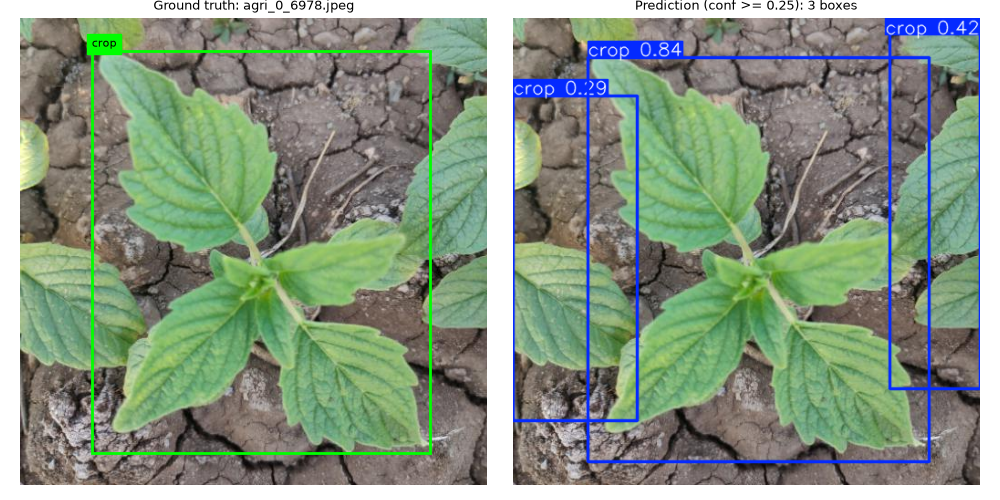

In [11]:
import csv
from pathlib import Path
from IPython.display import Image, display
from ultralytics import YOLO

model = YOLO("runs/detect/experiment/weights/best.pt")

with open("res/split.csv") as file:
    rows = list(csv.DictReader(file))
names = [r["image"] for r in rows if r["split"] == "test" and r["image"] == r["group"] + ".jpeg"]

differences = []
for name in names:
    label_path = Path("data/labels/test") / name.replace(".jpeg", ".txt")
    gt_count = len([line for line in label_path.read_text().splitlines() if line.strip()])
    result = model.predict(f"data/images/test/{name}", imgsz=640, conf=0.25, verbose=False)[0]
    differences.append((abs(gt_count - len(result.boxes)), name, gt_count, len(result.boxes)))

differences.sort(reverse=True)
for diff, name, gt_count, pred_count in differences[:10]:
    print(f"{name}: ground truth {gt_count}, predicted {pred_count}")

for diff, name, gt_count, pred_count in differences[:3]:
    display(Image(f"res/preds/{name.replace('.jpeg', '.png')}"))



%cd /content/Object_Detection
from IPython.display import Image, display

for name in ["agri_0_14", "agri_0_1499", "agri_0_6978"]:
    display(Image(f"res/preds/{name}.png"))


In [10]:
# Optional: copies the results to YOUR Google Drive (asks for a Drive login).
# Not needed to reproduce the project; you can skip this cell.
from google.colab import drive
drive.mount("/content/drive")

!mkdir -p /content/drive/MyDrive/Object_Detection
!cp -r runs/detect/baseline runs/detect/experiment /content/drive/MyDrive/Object_Detection/
!cp -r res/preds res/comparison.csv res/test_metrics.json /content/drive/MyDrive/Object_Detection/

Mounted at /content/drive
